In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile
from pathlib import Path

zip_path = Path("/content/drive/MyDrive/PathSnap/Student folder.zip")
extract_path = Path("/content/PathSnap_data")

if not extract_path.exists():
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

print("Extraction complete!")

Extraction complete!


In [3]:
import os

for root, dirs, files in os.walk(extract_path):
    print(root, len(files))
    if root.count(os.sep) - str(extract_path).count(os.sep) >= 2:
        dirs[:] = []


/content/PathSnap_data 0
/content/PathSnap_data/Student folder 0
/content/PathSnap_data/Student folder/train 0
/content/PathSnap_data/Student folder/student_test 0


In [10]:
from pathlib import Path

dataset_root = Path("/content/PathSnap_data/Student folder")

train_path = dataset_root / "train"
test_path = dataset_root / "student_test"

print("Dataset root exists:", dataset_root.exists())
print("Train directory exists:", train_path.exists())
print("Test directory exists:", test_path.exists())

Dataset root exists: True
Train directory exists: True
Test directory exists: True


In [11]:
trip_path = train_path / "00000043"

print("Trip:", trip_path.name)
print("\nFiles inside the trip:\n")

for file in sorted(trip_path.iterdir()):
    print(
        f"File: {file.name:25} | "
        f"Size: {file.stat().st_size:,} bytes"
    )

Trip: 00000043

Files inside the trip:

File: 00000043.arcs             | Size: 2,576,219 bytes
File: 00000043.nodes            | Size: 2,072,330 bytes
File: 00000043.route            | Size: 2,772 bytes
File: 00000043.track            | Size: 73,197 bytes


In [12]:
files = ["track", "nodes", "arcs", "route"]

for extension in files:
    file_path = trip_path / f"00000043.{extension}"

    print(f"\n{'='*60}")
    print(f"FILE: {extension.upper()}")
    print(f"{'='*60}")

    with open(file_path, "r") as f:
        for i, line in enumerate(f):
            print(repr(line.rstrip("\n")))
            if i == 4:
                break


FILE: TRACK
'4.977272\t51.894451\t1.000000'
'4.977274\t51.894789\t2.000000'
'4.977562\t51.895129\t3.000000'
'4.977636\t51.895351\t4.000000'
'4.977751\t51.895600\t5.000000'

FILE: NODES
'5.104270\t52.090548'
'5.109004\t52.095472'
'5.093261\t52.087438'
'5.100939\t52.084099'
'5.097848\t52.085884'

FILE: ARCS
'0\t26201'
'0\t107204'
'0\t26566'
'1\t102204'
'2\t130'

FILE: ROUTE
'3174'
'3665'
'3842'
'4511'
'177079'


In [13]:
# Count the number of records in each file
for extension in ["track", "nodes", "arcs", "route"]:
    file_path = trip_path / f"00000043.{extension}"

    with open(file_path, "r") as f:
        count = sum(1 for _ in f)

    print(f"{extension:8} → {count:,} records")

track    → 2,322 records
nodes    → 109,070 records
arcs     → 215,620 records
route    → 427 records


In [14]:
# Inspect the first few route IDs against the arc records

route_file = trip_path / "00000043.route"
arcs_file = trip_path / "00000043.arcs"

with open(route_file, "r") as f:
    route_ids = [int(line.strip()) for line in f if line.strip()]

with open(arcs_file, "r") as f:
    arc_lines = [line.strip() for line in f]

print("First 5 route IDs:", route_ids[:5])
print("\nTrying route IDs as arc row indices:\n")

for route_id in route_ids[:5]:
    if route_id < len(arc_lines):
        print(f"Route ID {route_id} → Arc row: {arc_lines[route_id]}")
    else:
        print(f"Route ID {route_id} is outside the arc file")

First 5 route IDs: [3174, 3665, 3842, 4511, 177079]

Trying route IDs as arc row indices:

Route ID 3174 → Arc row: 1548	1781
Route ID 3665 → Arc row: 1781	1873
Route ID 3842 → Arc row: 1873	2188
Route ID 4511 → Arc row: 2188	88938
Route ID 177079 → Arc row: 88938	3064


In [15]:
# Load all arcs as pairs of node IDs
arcs = []

with open(arcs_file, "r") as f:
    for line in f:
        if line.strip():
            source, destination = map(int, line.split())
            arcs.append((source, destination))

# Validate route indices
invalid_route_ids = [
    route_id for route_id in route_ids
    if route_id < 0 or route_id >= len(arcs)
]

# Check connectivity between consecutive route arcs
disconnected_pairs = []

for i in range(len(route_ids) - 1):
    current_arc = arcs[route_ids[i]]
    next_arc = arcs[route_ids[i + 1]]

    if current_arc[1] != next_arc[0]:
        disconnected_pairs.append({
            "position": i,
            "current_arc": current_arc,
            "next_arc": next_arc
        })

print("Total route entries:", len(route_ids))
print("Total arcs:", len(arcs))
print("Invalid route IDs:", len(invalid_route_ids))
print("Disconnected consecutive arcs:", len(disconnected_pairs))

print("\nFirst disconnected pairs:")
for pair in disconnected_pairs[:5]:
    print(pair)

Total route entries: 427
Total arcs: 215620
Invalid route IDs: 0
Disconnected consecutive arcs: 0

First disconnected pairs:


In [17]:
import pandas as pd
from pathlib import Path

dataset_root = Path("/content/PathSnap_data/Student folder")
extensions = ["track", "nodes", "arcs", "route"]
rows = []

for partition in ["train", "student_test"]:
    for trip_dir in sorted((dataset_root / partition).iterdir()):
        if not trip_dir.is_dir():
            continue

        trip_id = trip_dir.name
        row = {"trip_id": trip_id, "partition": partition}

        for ext in extensions:
            file = trip_dir / f"{trip_id}.{ext}"
            row[f"{ext}_exists"] = file.exists()

            if file.exists():
                row[f"{ext}_size_bytes"] = file.stat().st_size
                with open(file, "r") as f:
                    row[f"{ext}_records"] = sum(1 for _ in f)
            else:
                row[f"{ext}_size_bytes"] = 0
                row[f"{ext}_records"] = 0

        rows.append(row)

inventory = pd.DataFrame(rows)

# Summary
print("TOTAL TRIPS:", len(inventory))
print("\nTRIPS BY PARTITION:")
print(inventory["partition"].value_counts())

print("\nTOTAL RECORDS:")
for ext in extensions:
    print(f"{ext}: {inventory[f'{ext}_records'].sum():,}")

print("\nMISSING FILES:")
for ext in extensions:
    print(f"{ext}: {(~inventory[f'{ext}_exists']).sum()}")

display(inventory.head())

# Save results
OUTPUT_DIR = Path("/content/drive/MyDrive/PathSnap/Hemant_EDA")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
inventory.to_csv(OUTPUT_DIR / "dataset_inventory.csv", index=False)

print("\nSaved dataset_inventory.csv to Google Drive!")

TOTAL TRIPS: 90

TRIPS BY PARTITION:
partition
train           80
student_test    10
Name: count, dtype: int64

TOTAL RECORDS:
track: 227,577
nodes: 2,024,174
arcs: 4,061,945
route: 34,813

MISSING FILES:
track: 0
nodes: 0
arcs: 0
route: 0


,trip_id,partition,track_exists,track_size_bytes,track_records,nodes_exists,nodes_size_bytes,nodes_records,arcs_exists,arcs_size_bytes,arcs_records,route_exists,route_size_bytes,route_records
0,00000001,train,True,40975,1315,True,1687371,88809,True,1948474,165790,True,3119,525
1,00000002,train,True,238085,7243,True,158720,7936,True,156519,16139,True,1398,262
2,00000003,train,True,26164,821,True,182760,9138,True,175733,18028,True,411,79
3,00000004,train,True,34982,1064,True,147000,7350,True,149738,15499,True,1582,320
4,00000005,train,True,33378,1045,True,17960,898,True,12351,1579,True,421,105



Saved dataset_inventory.csv to Google Drive!


In [18]:
import pandas as pd
import numpy as np
from pathlib import Path

quality_rows = []

for partition in ["train", "student_test"]:
    for trip_dir in sorted((dataset_root / partition).iterdir()):
        if not trip_dir.is_dir():
            continue

        tid = trip_dir.name

        track_file = trip_dir / f"{tid}.track"
        nodes_file = trip_dir / f"{tid}.nodes"
        arcs_file  = trip_dir / f"{tid}.arcs"
        route_file = trip_dir / f"{tid}.route"

        # Load data
        track = pd.read_csv(track_file, sep=r"\s+", header=None)
        nodes = pd.read_csv(nodes_file, sep=r"\s+", header=None)
        arcs  = pd.read_csv(arcs_file, sep=r"\s+", header=None)
        route = pd.read_csv(route_file, header=None)

        # Track: longitude, latitude, time
        lon = track.iloc[:, 0]
        lat = track.iloc[:, 1]
        timestamp = track.iloc[:, 2]

        # GPS checks
        invalid_coordinates = (
            (lat < -90) | (lat > 90) |
            (lon < -180) | (lon > 180)
        ).sum()

        missing_track_values = track.isna().sum().sum()
        duplicate_gps_rows = track.duplicated().sum()
        duplicate_timestamps = timestamp.duplicated().sum()

        # Time interval checks
        time_diff = timestamp.diff().dropna()

        nonpositive_intervals = (time_diff <= 0).sum()
        gaps_over_1 = (time_diff > 1).sum()
        gaps_over_10 = (time_diff > 10).sum()

        # Road graph checks
        arc_array = arcs.to_numpy(dtype=int)
        route_ids = route.iloc[:, 0].to_numpy(dtype=int)

        invalid_route_ids = (
            (route_ids < 0) | (route_ids >= len(arc_array))
        ).sum()

        # Only validate route connectivity when IDs are valid
        disconnected_route_pairs = 0

        if invalid_route_ids == 0 and len(route_ids) > 1:
            selected_arcs = arc_array[route_ids]
            disconnected_route_pairs = (
                selected_arcs[:-1, 1] != selected_arcs[1:, 0]
            ).sum()

        # Check whether arc node references are within node index bounds
        invalid_arc_node_refs = (
            (arc_array < 0) | (arc_array >= len(nodes))
        ).sum()

        # Store one result row per trip
        quality_rows.append({
            "trip_id": tid,
            "partition": partition,
            "track_records": len(track),
            "nodes_records": len(nodes),
            "arcs_records": len(arcs),
            "route_records": len(route),
            "missing_track_values": missing_track_values,
            "invalid_coordinates": int(invalid_coordinates),
            "duplicate_gps_rows": int(duplicate_gps_rows),
            "duplicate_timestamps": int(duplicate_timestamps),
            "nonpositive_time_intervals": int(nonpositive_intervals),
            "gaps_over_1": int(gaps_over_1),
            "gaps_over_10": int(gaps_over_10),
            "invalid_route_ids": int(invalid_route_ids),
            "disconnected_route_pairs": int(disconnected_route_pairs),
            "invalid_arc_node_refs": int(invalid_arc_node_refs)
        })

quality_report = pd.DataFrame(quality_rows)

# Dataset-wide summary
numeric_cols = quality_report.select_dtypes(include="number").columns

quality_summary = quality_report[numeric_cols].sum()

print("DATA QUALITY AUDIT COMPLETE")
print("=" * 50)
print("Trips audited:", len(quality_report))

print("\nDATASET-WIDE ISSUE COUNTS:")
display(quality_summary.to_frame("total"))

print("\nTRIPS WITH ANY GPS ISSUE:")
gps_issue_cols = [
    "missing_track_values",
    "invalid_coordinates",
    "duplicate_gps_rows",
    "duplicate_timestamps",
    "nonpositive_time_intervals"
]
display(
    quality_report[
        quality_report[gps_issue_cols].sum(axis=1) > 0
    ][["trip_id", "partition"] + gps_issue_cols]
)

# Save
OUTPUT_DIR = Path("/content/drive/MyDrive/PathSnap/Hemant_EDA")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

quality_report.to_csv(OUTPUT_DIR / "data_quality_report.csv", index=False)
quality_summary.to_csv(OUTPUT_DIR / "data_quality_summary.csv")

print("\nSaved quality report and summary to Google Drive.")

DATA QUALITY AUDIT COMPLETE
Trips audited: 90

DATASET-WIDE ISSUE COUNTS:


,total
track_records,227577
nodes_records,2024174
arcs_records,4061945
route_records,34813
missing_track_values,0
invalid_coordinates,0
duplicate_gps_rows,0
duplicate_timestamps,0
nonpositive_time_intervals,0
gaps_over_1,7550



TRIPS WITH ANY GPS ISSUE:


,trip_id,partition,missing_track_values,invalid_coordinates,duplicate_gps_rows,duplicate_timestamps,nonpositive_time_intervals



Saved quality report and summary to Google Drive.


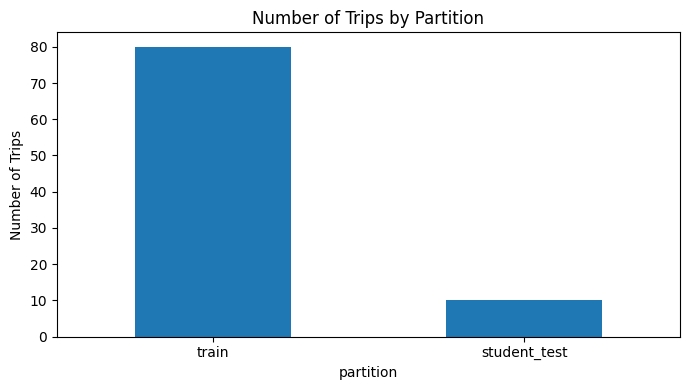

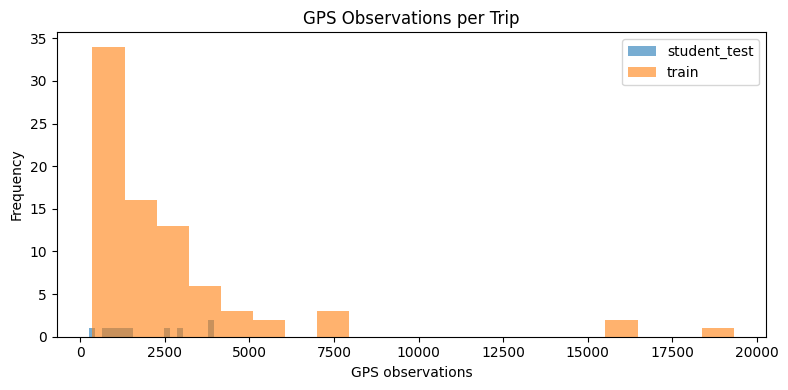

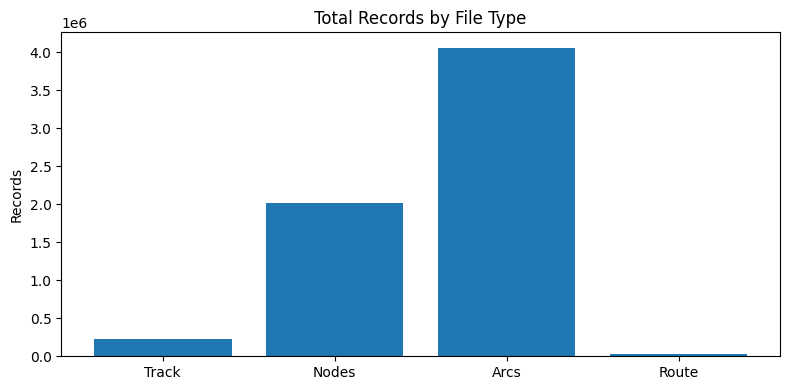

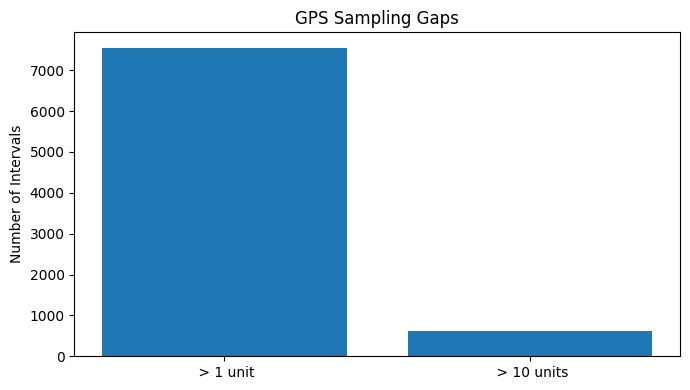

Trips with disconnected route pairs:


,trip_id,partition,disconnected_route_pairs
1,00000002,train,1
14,00000019,train,3
26,00000033,train,1
33,00000041,train,1
34,00000042,train,1
55,00000069,train,1
60,00000075,train,2
63,00000080,train,1
69,00000086,train,1
71,00000089,train,1



Final report saved: /content/drive/MyDrive/PathSnap/Hemant_EDA/data_quality_findings.md

All charts and reports saved in: /content/drive/MyDrive/PathSnap/Hemant_EDA


In [19]:
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("/content/drive/MyDrive/PathSnap/Hemant_EDA")
OUT.mkdir(parents=True, exist_ok=True)

# ---------- 1. Trip counts by partition ----------
counts = inventory["partition"].value_counts()

plt.figure(figsize=(7,4))
counts.plot(kind="bar")
plt.title("Number of Trips by Partition")
plt.ylabel("Number of Trips")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT / "trips_by_partition.png", dpi=150)
plt.show()

# ---------- 2. GPS observations per trip ----------
plt.figure(figsize=(8,4))
inventory.groupby("partition")["track_records"].plot(
    kind="hist", alpha=0.6, legend=True, bins=20
)
plt.title("GPS Observations per Trip")
plt.xlabel("GPS observations")
plt.tight_layout()
plt.savefig(OUT / "gps_observations_distribution.png", dpi=150)
plt.show()

# ---------- 3. Total records by data type ----------
record_totals = {
    "Track": inventory["track_records"].sum(),
    "Nodes": inventory["nodes_records"].sum(),
    "Arcs": inventory["arcs_records"].sum(),
    "Route": inventory["route_records"].sum()
}

plt.figure(figsize=(8,4))
plt.bar(record_totals.keys(), record_totals.values())
plt.title("Total Records by File Type")
plt.ylabel("Records")
plt.tight_layout()
plt.savefig(OUT / "records_by_file_type.png", dpi=150)
plt.show()

# ---------- 4. GPS gaps ----------
gap_totals = {
    " > 1 unit": quality_report["gaps_over_1"].sum(),
    " > 10 units": quality_report["gaps_over_10"].sum()
}

plt.figure(figsize=(7,4))
plt.bar(gap_totals.keys(), gap_totals.values())
plt.title("GPS Sampling Gaps")
plt.ylabel("Number of Intervals")
plt.tight_layout()
plt.savefig(OUT / "gps_gaps.png", dpi=150)
plt.show()

# ---------- Route connectivity issues ----------
problem_trips = quality_report[
    quality_report["disconnected_route_pairs"] > 0
][["trip_id", "partition", "disconnected_route_pairs"]]

print("Trips with disconnected route pairs:")
display(problem_trips)

# ---------- Summary report ----------
findings = f"""
# PathSnap — Dataset Inventory & Data Quality Findings

## Dataset Overview
- Total trips: {len(inventory)}
- Training trips: {(inventory['partition'] == 'train').sum()}
- Student test trips: {(inventory['partition'] == 'student_test').sum()}
- GPS observations: {inventory['track_records'].sum():,}
- Road nodes: {inventory['nodes_records'].sum():,}
- Road arcs: {inventory['arcs_records'].sum():,}
- Reference route entries: {inventory['route_records'].sum():,}

## Structural Integrity
- Missing track files: {(~inventory['track_exists']).sum()}
- Missing node files: {(~inventory['nodes_exists']).sum()}
- Missing arc files: {(~inventory['arcs_exists']).sum()}
- Missing route files: {(~inventory['route_exists']).sum()}

## GPS Quality
- Missing GPS values: {quality_report['missing_track_values'].sum()}
- Invalid coordinates: {quality_report['invalid_coordinates'].sum()}
- Duplicate GPS rows: {quality_report['duplicate_gps_rows'].sum()}
- Duplicate timestamps: {quality_report['duplicate_timestamps'].sum()}
- Nonpositive intervals: {quality_report['nonpositive_time_intervals'].sum()}
- Intervals > 1 time unit: {quality_report['gaps_over_1'].sum()}
- Intervals > 10 time units: {quality_report['gaps_over_10'].sum()}

**Note:** The unit and semantic meaning of the track's third column
have not yet been verified. Gap thresholds are therefore expressed
in data units, not confirmed seconds.

## Road Network and Route Integrity
- Invalid route IDs: {quality_report['invalid_route_ids'].sum()}
- Disconnected consecutive route arc pairs: {quality_report['disconnected_route_pairs'].sum()}
- Invalid arc-to-node references: {quality_report['invalid_arc_node_refs'].sum()}
- Trips with route connectivity issues: {len(problem_trips)}

## Preliminary Conclusion
The dataset is structurally complete across all discovered trips.
Basic GPS checks found no missing values, invalid coordinates,
duplicate rows/timestamps, or nonpositive intervals.

Some GPS observation intervals are larger than the selected thresholds.
A small number of consecutive route arcs fail the connectivity check
and should be investigated before model development.

No original data has been modified.
"""

report_path = OUT / "data_quality_findings.md"
report_path.write_text(findings, encoding="utf-8")

print("\nFinal report saved:", report_path)
print("\nAll charts and reports saved in:", OUT)

In [20]:
from pathlib import Path
import pandas as pd

dataset_root = Path("/content/PathSnap_data/Student folder")

affected = quality_report[
    quality_report["disconnected_route_pairs"] > 0
]

for _, row in affected.iterrows():
    trip_id = row["trip_id"]
    partition = row["partition"]

    trip_dir = dataset_root / partition / trip_id

    arcs = pd.read_csv(trip_dir / f"{trip_id}.arcs",
                      sep=r"\s+", header=None).to_numpy()
    route = pd.read_csv(trip_dir / f"{trip_id}.route",
                        header=None).iloc[:, 0].to_numpy()

    selected = arcs[route]
    breaks = selected[:-1, 1] != selected[1:, 0]
    break_indices = [i for i, value in enumerate(breaks) if value]

    print(f"\n{'='*60}")
    print(f"Trip: {trip_id} | Partition: {partition}")
    print(f"Connectivity breaks: {len(break_indices)}")

    for i in break_indices:
        print(f"\nRoute position {i} -> {i+1}")
        print(f"Arc row {route[i]}: {selected[i]}")
        print(f"Arc row {route[i+1]}: {selected[i+1]}")
        print(f"End node {selected[i][1]} != Start node {selected[i+1][0]}")


Trip: 00000002 | Partition: train
Connectivity breaks: 1

Route position 53 -> 54
Arc row 1848: [ 846 5059]
Arc row 10863: [5289 5290]
End node 5059 != Start node 5289

Trip: 00000019 | Partition: train
Connectivity breaks: 3

Route position 94 -> 95
Arc row 85589: [40766   849]
Arc row 51027: [23488 25511]
End node 849 != Start node 23488

Route position 151 -> 152
Arc row 55059: [25416 25413]
Arc row 55050: [25408   889]
End node 25413 != Start node 25408

Route position 300 -> 301
Arc row 953: [  434 10107]
Arc row 23709: [10862   435]
End node 10107 != Start node 10862

Trip: 00000033 | Partition: train
Connectivity breaks: 1

Route position 164 -> 165
Arc row 1003: [ 563 1283]
Arc row 1002: [563 553]
End node 1283 != Start node 563

Trip: 00000041 | Partition: train
Connectivity breaks: 1

Route position 12 -> 13
Arc row 1264: [779 349]
Arc row 519: [348 290]
End node 349 != Start node 348

Trip: 00000042 | Partition: train
Connectivity breaks: 1

Route position 1212 -> 1213
Arc 

TRIP-LEVEL SEQUENCE SUMMARY


,trip_id,partition,gps_points,third_col_min,third_col_max,third_col_span,mean_interval,median_interval,std_interval,min_interval,max_interval,intervals_gt_1,intervals_gt_10,nonpositive_intervals
0,00000001,train,1315,1.0,1358.000,1357.000,1.032725,1.0,0.446355,1.0,16.0,25,1,0
1,00000002,train,7243,1.0,8934.156,8933.156,1.233521,1.0,3.554537,1.0,160.0,184,41,0
2,00000003,train,821,1.0,824.000,823.000,1.003659,1.0,0.060412,1.0,2.0,3,0,0
3,00000004,train,1064,1.0,5218.000,5217.000,4.907808,1.0,5.857614,1.0,51.0,491,215,0
4,00000005,train,1045,1.0,1045.000,1044.000,1.000000,1.0,0.000000,1.0,1.0,0,0,0



SUMMARY BY PARTITION


gps_points                     third_col_span                   \
                   mean  median  min    max           mean    median    min   
partition                                                                     
student_test   1916.000  1420.0  262   3958       2025.000  1809.500  265.0   
train          2605.212  1529.0  361  19313       5680.404  1710.001  451.0   

                       mean_interval         ... max_interval            \
                   max          mean median  ...          min       max   
partition                                    ...                          
student_test    4000.0         1.091  1.001  ...          1.0     210.0   
train         154030.0         5.102  1.059  ...          1.0  153064.0   

             intervals_gt_1                  intervals_gt_10                  
                       mean median min   max            mean median min  max  
partition                                                                     
student_test         26.400    1.0   0   206           2.700    0.0   0   24  
train                91.075   15.5   0  1268           7.375    0.5   0  215  

[2 rows x 28 columns]

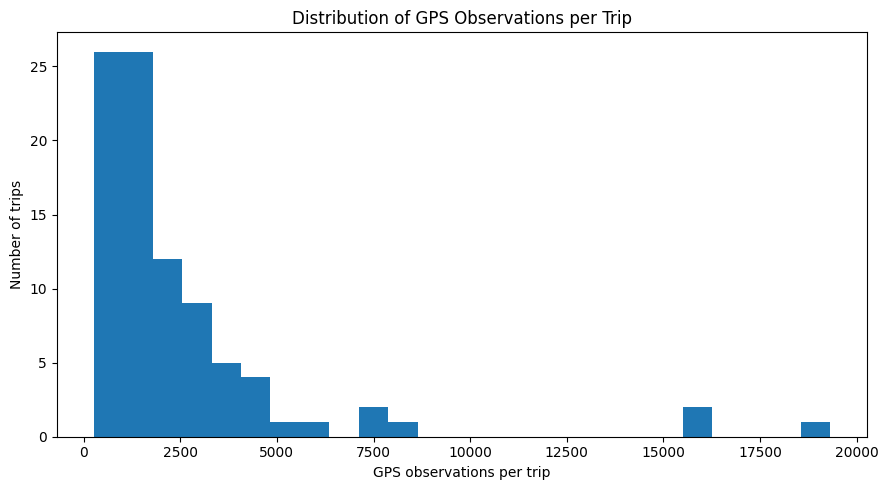

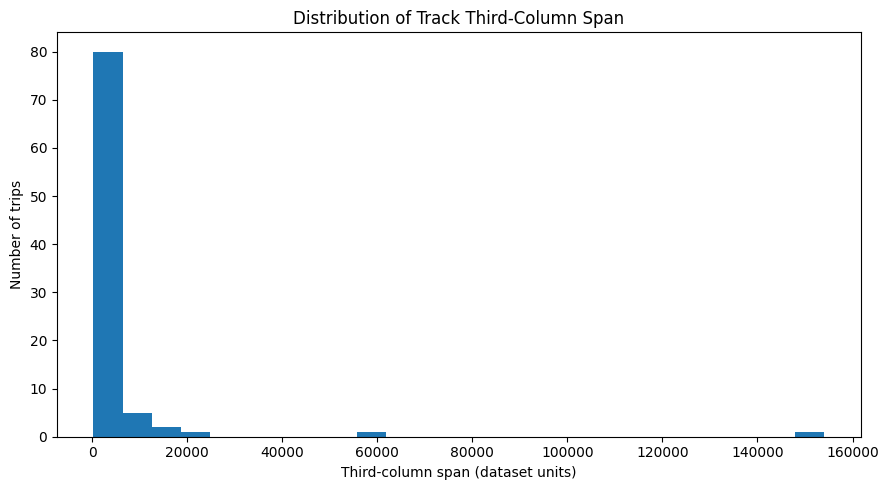

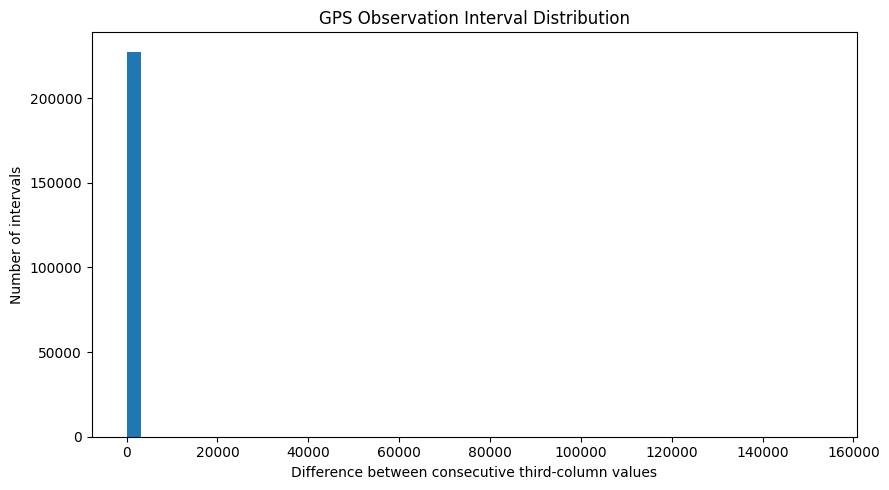

<Figure size 800x500 with 0 Axes>

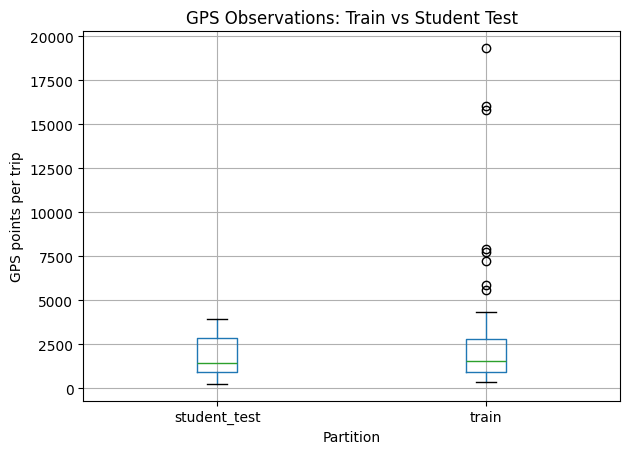


Saved Phase 2 outputs to: /content/drive/MyDrive/PathSnap/Hemant_EDA


In [21]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/content/PathSnap_data/Student folder")
OUT = Path("/content/drive/MyDrive/PathSnap/Hemant_EDA")
OUT.mkdir(parents=True, exist_ok=True)

rows = []

for partition in ["train", "student_test"]:
    for trip_dir in sorted((ROOT / partition).iterdir()):
        if not trip_dir.is_dir():
            continue

        trip_id = trip_dir.name
        track_file = trip_dir / f"{trip_id}.track"

        track = pd.read_csv(track_file, sep=r"\s+", header=None)
        third = track.iloc[:, 2]
        diff = third.diff().dropna()

        rows.append({
            "trip_id": trip_id,
            "partition": partition,
            "gps_points": len(track),
            "third_col_min": third.min(),
            "third_col_max": third.max(),
            "third_col_span": third.max() - third.min(),
            "mean_interval": diff.mean() if len(diff) else np.nan,
            "median_interval": diff.median() if len(diff) else np.nan,
            "std_interval": diff.std() if len(diff) else np.nan,
            "min_interval": diff.min() if len(diff) else np.nan,
            "max_interval": diff.max() if len(diff) else np.nan,
            "intervals_gt_1": (diff > 1).sum(),
            "intervals_gt_10": (diff > 10).sum(),
            "nonpositive_intervals": (diff <= 0).sum()
        })

temporal = pd.DataFrame(rows)
temporal.to_csv(OUT / "temporal_sequence_summary.csv", index=False)

print("TRIP-LEVEL SEQUENCE SUMMARY")
display(temporal.head())

print("\nSUMMARY BY PARTITION")
display(
    temporal.groupby("partition")[
        ["gps_points", "third_col_span", "mean_interval",
         "median_interval", "max_interval", "intervals_gt_1",
         "intervals_gt_10"]
    ].agg(["mean", "median", "min", "max"]).round(3)
)

# 1. GPS observation count per trip
plt.figure(figsize=(9, 5))
plt.hist(temporal["gps_points"], bins=25)
plt.xlabel("GPS observations per trip")
plt.ylabel("Number of trips")
plt.title("Distribution of GPS Observations per Trip")
plt.tight_layout()
plt.savefig(OUT / "phase2_gps_points_distribution.png", dpi=160)
plt.show()

# 2. Third-column span per trip (units not verified)
plt.figure(figsize=(9, 5))
plt.hist(temporal["third_col_span"], bins=25)
plt.xlabel("Third-column span (dataset units)")
plt.ylabel("Number of trips")
plt.title("Distribution of Track Third-Column Span")
plt.tight_layout()
plt.savefig(OUT / "phase2_third_column_span.png", dpi=160)
plt.show()

# 3. Interval distribution
all_intervals = []

for partition in ["train", "student_test"]:
    for trip_dir in sorted((ROOT / partition).iterdir()):
        if not trip_dir.is_dir():
            continue
        trip_id = trip_dir.name
        track = pd.read_csv(
            trip_dir / f"{trip_id}.track",
            sep=r"\s+", header=None
        )
        diff = track.iloc[:, 2].diff().dropna()
        all_intervals.extend(diff.tolist())

plt.figure(figsize=(9, 5))
plt.hist(all_intervals, bins=50)
plt.xlabel("Difference between consecutive third-column values")
plt.ylabel("Number of intervals")
plt.title("GPS Observation Interval Distribution")
plt.tight_layout()
plt.savefig(OUT / "phase2_interval_distribution.png", dpi=160)
plt.show()

# 4. Compare observation counts between train and test
plt.figure(figsize=(8, 5))
temporal.boxplot(column="gps_points", by="partition")
plt.title("GPS Observations: Train vs Student Test")
plt.suptitle("")
plt.xlabel("Partition")
plt.ylabel("GPS points per trip")
plt.tight_layout()
plt.savefig(OUT / "phase2_train_test_gps_comparison.png", dpi=160)
plt.show()

print("\nSaved Phase 2 outputs to:", OUT)


TOTAL GPS POINTS: 227577
GEOGRAPHIC BOUNDS:
Longitude: -100.418538 to 137.237029
Latitude: -34.640291 to 61.69959

SPATIAL SUMMARY:


,trip_id,partition,gps_points,min_lon,max_lon,min_lat,max_lat,lon_range,lat_range,start_lon,start_lat,end_lon,end_lat
0,00000001,train,1315,8.570524,8.647860,49.844053,50.211882,0.077336,0.367829,8.595203,49.844053,8.570524,50.194015
1,00000002,train,7243,10.999961,11.050902,47.658344,47.695459,0.050941,0.037115,11.043183,47.658577,11.003208,47.688686
2,00000003,train,821,37.154202,37.201595,55.977135,56.007585,0.047393,0.030450,37.201398,56.007471,37.155306,55.977440
3,00000004,train,1064,12.342280,12.459615,52.590308,52.718960,0.117335,0.128652,12.412766,52.718960,12.342589,52.590308
4,00000005,train,1045,35.485577,35.544315,49.357581,49.613085,0.058738,0.255504,35.544315,49.613085,35.508590,49.357645



SUMMARY BY PARTITION:


gps_points                     lon_range                      \
                   mean  median  min    max      mean    median       min   
partition                                                                   
student_test  1916.0000  1420.0  262   3958  0.149993  0.073533  0.032497   
train         2605.2125  1529.0  361  19313  0.187278  0.091744  0.013694   

                       lat_range                                
                   max      mean    median       min       max  
partition                                                       
student_test  0.715028  0.083058  0.053157  0.016914  0.241213  
train         1.103908  0.107771  0.047233  0.007844  0.678126

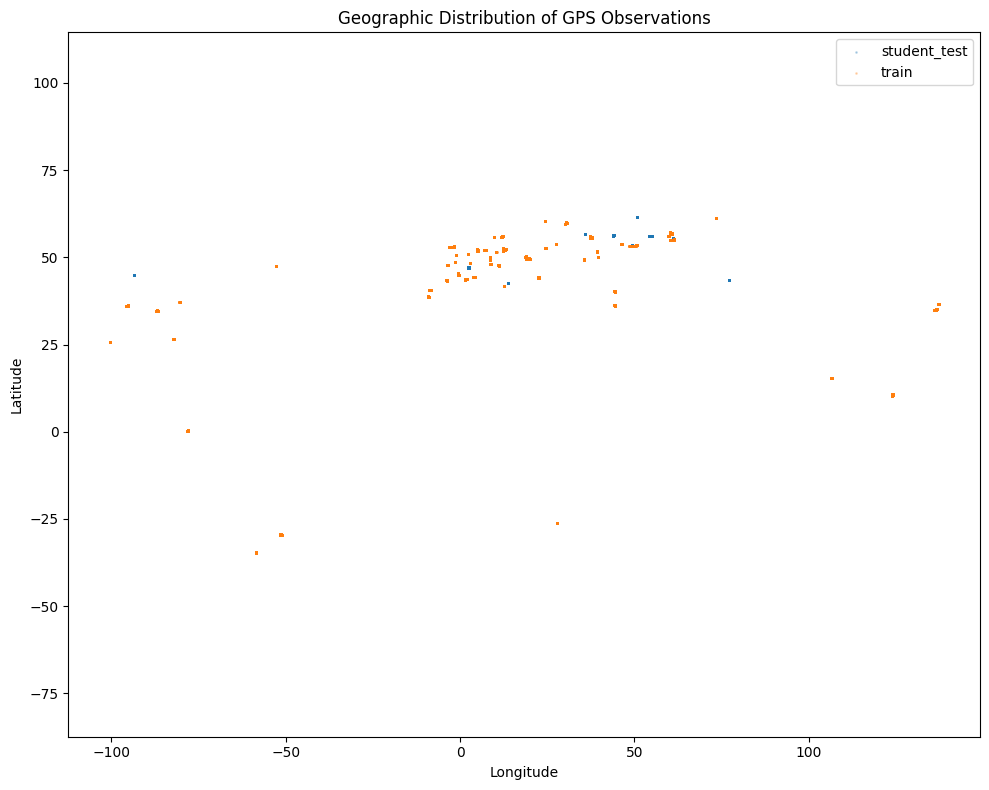

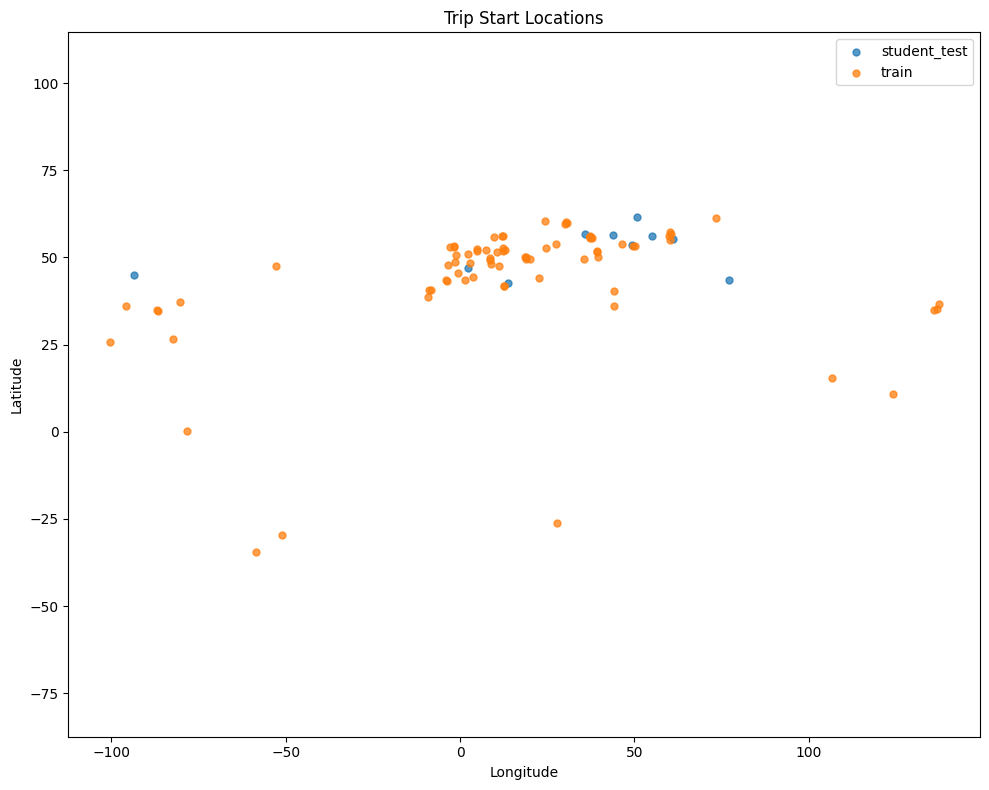

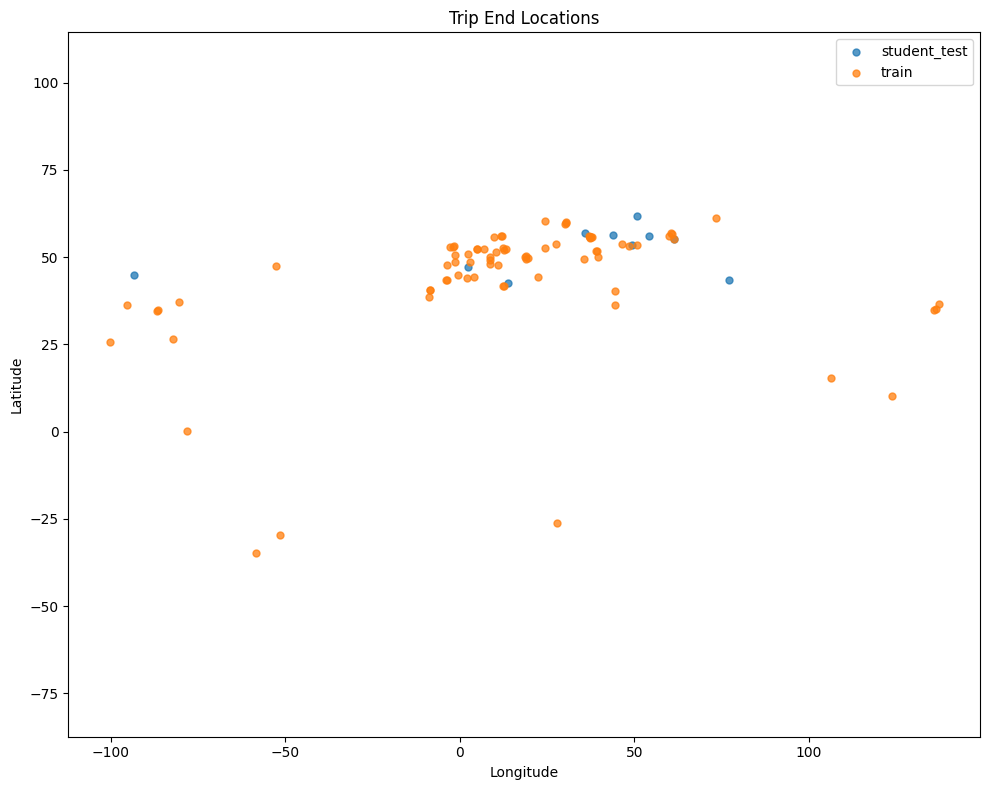

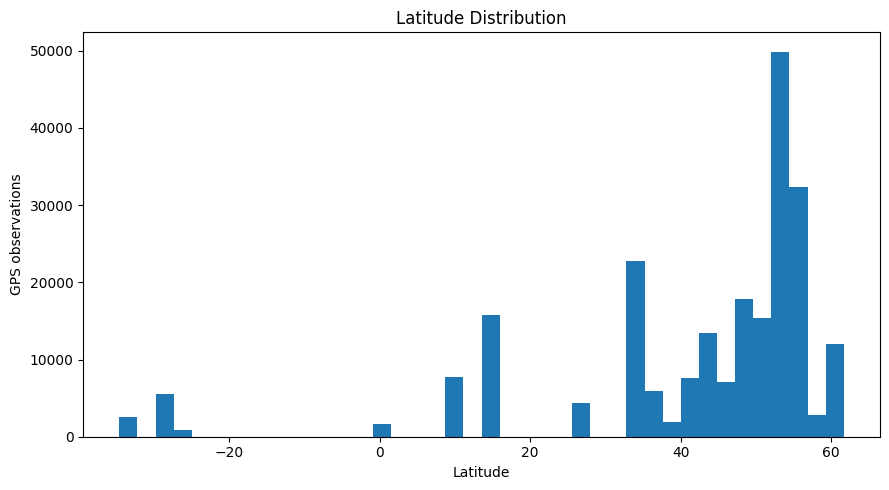

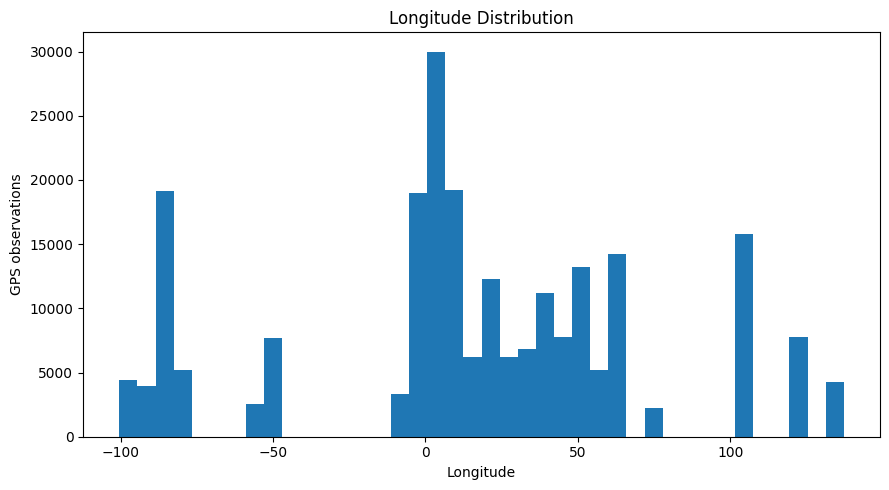

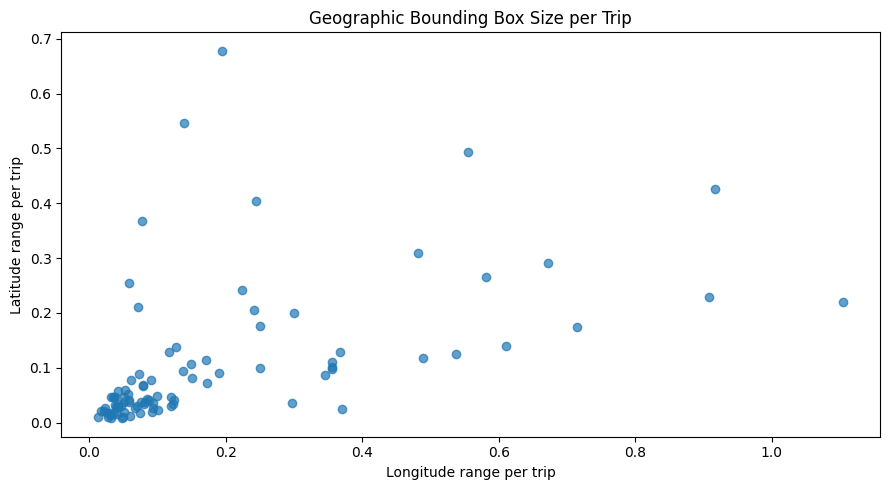


Phase 3 outputs saved to: /content/drive/MyDrive/PathSnap/Hemant_EDA


In [22]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/content/PathSnap_data/Student folder")
OUT = Path("/content/drive/MyDrive/PathSnap/Hemant_EDA")
OUT.mkdir(parents=True, exist_ok=True)

gps_frames = []
spatial_rows = []

for partition in ["train", "student_test"]:
    for trip_dir in sorted((ROOT / partition).iterdir()):
        if not trip_dir.is_dir():
            continue

        trip_id = trip_dir.name
        track_file = trip_dir / f"{trip_id}.track"

        track = pd.read_csv(track_file, sep=r"\s+", header=None)
        track.columns = ["longitude", "latitude", "sequence"]

        track["trip_id"] = trip_id
        track["partition"] = partition

        gps_frames.append(track)

        spatial_rows.append({
            "trip_id": trip_id,
            "partition": partition,
            "gps_points": len(track),
            "min_lon": track["longitude"].min(),
            "max_lon": track["longitude"].max(),
            "min_lat": track["latitude"].min(),
            "max_lat": track["latitude"].max(),
            "lon_range": track["longitude"].max() - track["longitude"].min(),
            "lat_range": track["latitude"].max() - track["latitude"].min(),
            "start_lon": track.iloc[0]["longitude"],
            "start_lat": track.iloc[0]["latitude"],
            "end_lon": track.iloc[-1]["longitude"],
            "end_lat": track.iloc[-1]["latitude"]
        })

gps = pd.concat(gps_frames, ignore_index=True)
spatial = pd.DataFrame(spatial_rows)

spatial.to_csv(OUT / "spatial_trip_summary.csv", index=False)

print("TOTAL GPS POINTS:", len(gps))
print("GEOGRAPHIC BOUNDS:")
print("Longitude:", gps["longitude"].min(), "to", gps["longitude"].max())
print("Latitude:", gps["latitude"].min(), "to", gps["latitude"].max())

print("\nSPATIAL SUMMARY:")
display(spatial.head())

print("\nSUMMARY BY PARTITION:")
display(
    spatial.groupby("partition")[
        ["gps_points", "lon_range", "lat_range"]
    ].agg(["mean", "median", "min", "max"]).round(6)
)

# 1. All GPS locations
plt.figure(figsize=(10, 8))
for partition, data in gps.groupby("partition"):
    plt.scatter(
        data["longitude"],
        data["latitude"],
        s=1,
        alpha=0.25,
        label=partition
    )
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographic Distribution of GPS Observations")
plt.legend()
plt.axis("equal")
plt.tight_layout()
plt.savefig(OUT / "phase3_all_gps_locations.png", dpi=180)
plt.show()

# 2. Trip start locations
plt.figure(figsize=(10, 8))
for partition, data in spatial.groupby("partition"):
    plt.scatter(
        data["start_lon"],
        data["start_lat"],
        s=25,
        alpha=0.75,
        label=partition
    )
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Trip Start Locations")
plt.legend()
plt.axis("equal")
plt.tight_layout()
plt.savefig(OUT / "phase3_trip_starts.png", dpi=180)
plt.show()

# 3. Trip end locations
plt.figure(figsize=(10, 8))
for partition, data in spatial.groupby("partition"):
    plt.scatter(
        data["end_lon"],
        data["end_lat"],
        s=25,
        alpha=0.75,
        label=partition
    )
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Trip End Locations")
plt.legend()
plt.axis("equal")
plt.tight_layout()
plt.savefig(OUT / "phase3_trip_ends.png", dpi=180)
plt.show()

# 4. Latitude distribution
plt.figure(figsize=(9, 5))
plt.hist(gps["latitude"], bins=40)
plt.xlabel("Latitude")
plt.ylabel("GPS observations")
plt.title("Latitude Distribution")
plt.tight_layout()
plt.savefig(OUT / "phase3_latitude_distribution.png", dpi=180)
plt.show()

# 5. Longitude distribution
plt.figure(figsize=(9, 5))
plt.hist(gps["longitude"], bins=40)
plt.xlabel("Longitude")
plt.ylabel("GPS observations")
plt.title("Longitude Distribution")
plt.tight_layout()
plt.savefig(OUT / "phase3_longitude_distribution.png", dpi=180)
plt.show()

# 6. Geographic spread per trip
plt.figure(figsize=(9, 5))
plt.scatter(spatial["lon_range"], spatial["lat_range"], alpha=0.7)
plt.xlabel("Longitude range per trip")
plt.ylabel("Latitude range per trip")
plt.title("Geographic Bounding Box Size per Trip")
plt.tight_layout()
plt.savefig(OUT / "phase3_trip_geographic_spread.png", dpi=180)
plt.show()

print("\nPhase 3 outputs saved to:", OUT)


ROAD NETWORK SUMMARY


,trip_id,partition,nodes,arcs,unique_arcs,duplicate_arcs,self_loops,isolated_nodes,source_only_nodes,sink_only_nodes,weak_components,largest_component_nodes,largest_component_fraction,mean_in_degree,mean_out_degree,max_in_degree,max_out_degree
0,00000001,train,88809,165790,165498,292,0,0,69,81,175,86854,0.977986,1.866815,1.866815,6,6
1,00000002,train,7936,16139,16139,0,0,0,0,0,14,7750,0.976562,2.033644,2.033644,5,5
2,00000003,train,9138,18028,18022,6,0,0,7,6,42,8625,0.943861,1.972861,1.972861,7,7
3,00000004,train,7350,15499,15494,5,0,0,1,0,12,7254,0.986939,2.108707,2.108707,5,5
4,00000005,train,898,1579,1579,0,0,0,2,2,3,888,0.988864,1.758352,1.758352,4,4



AGGREGATE SUMMARY


nodes                           arcs                 \
                    mean  median   min     max     mean   median   min   
partition                                                                
student_test   9068.9000  6596.5  1770   26635  18504.1  13145.0  3577   
train         24168.5625  9608.0   299  155003  48461.3  19526.5   649   

                     duplicate_arcs         ... sink_only_nodes      \
                 max           mean median  ...             min max   
partition                                   ...                       
student_test   56027        12.8000    3.5  ...               0  19   
train         307392        22.1875    2.0  ...               0  81   

             weak_components                 largest_component_fraction  \
                        mean median min  max                       mean   
partition                                                                 
student_test         22.7000   11.0   5  100                     0.9639   
train                39.0125   20.0   1  421                     0.9690   

                                      
              median     min     max  
partition                             
student_test  0.9706  0.8740  0.9907  
train         0.9811  0.6928  1.0000  

[2 rows x 36 columns]

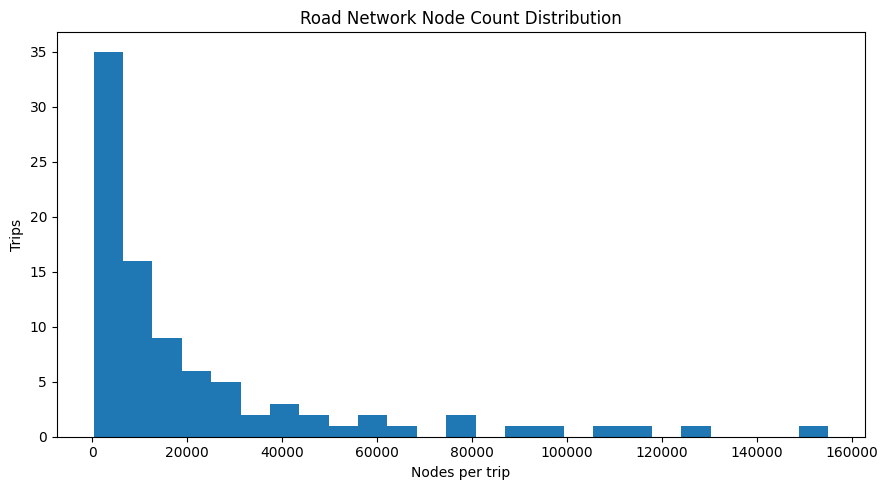

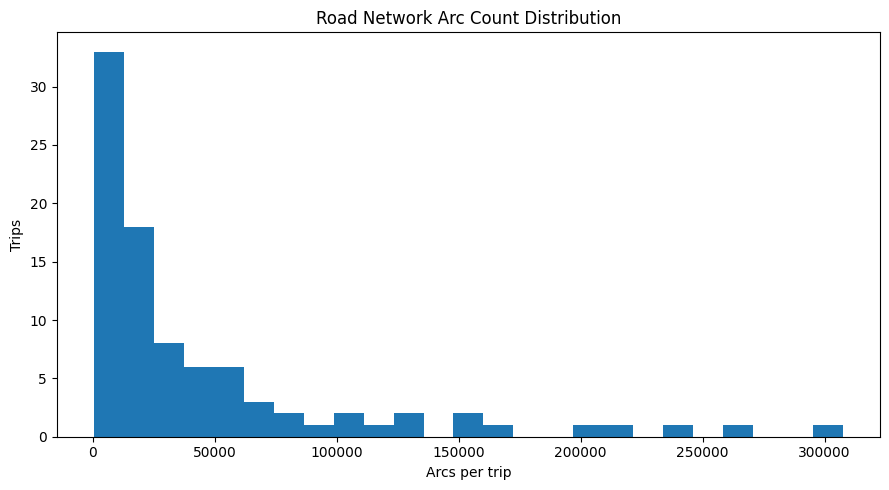

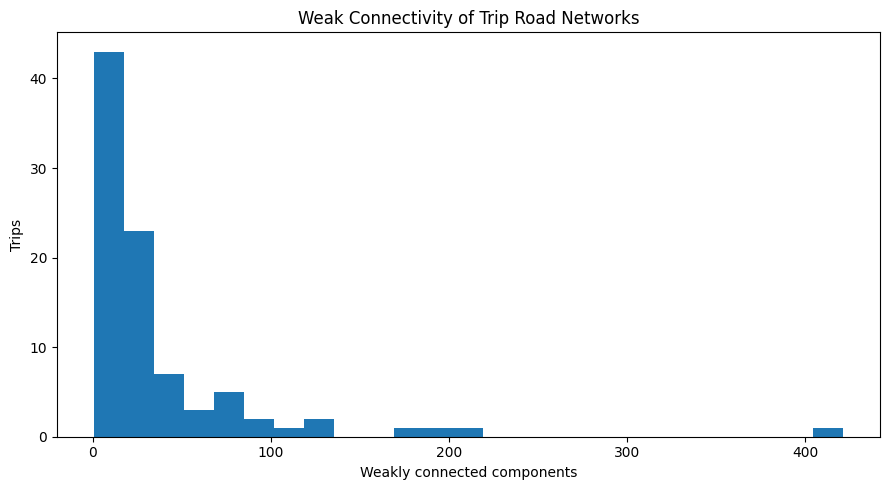

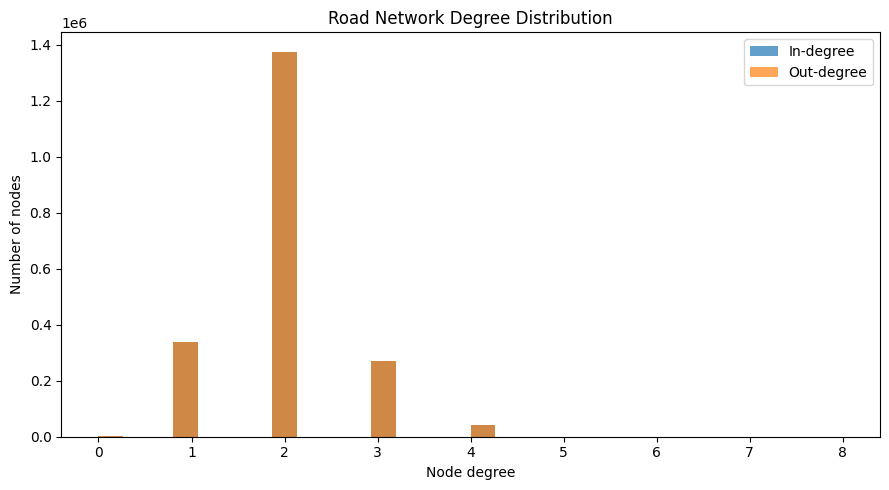

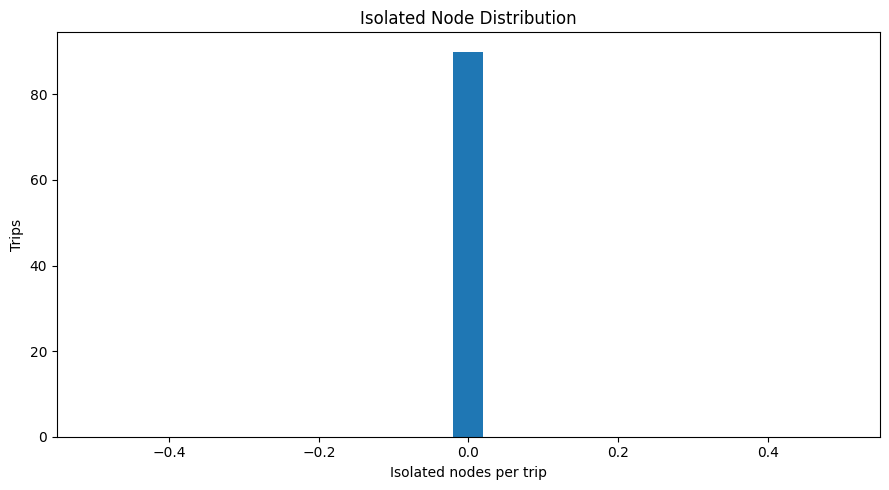

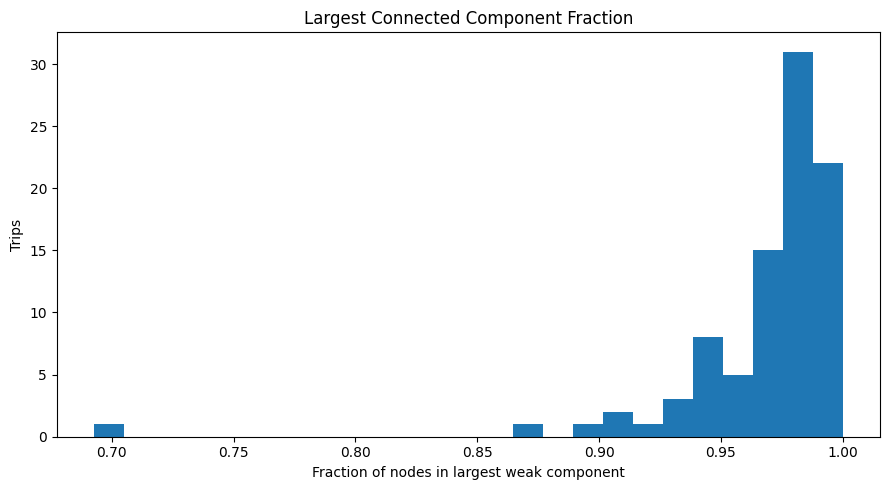


Phase 4 outputs saved to: /content/drive/MyDrive/PathSnap/Hemant_EDA


In [23]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

ROOT = Path("/content/PathSnap_data/Student folder")
OUT = Path("/content/drive/MyDrive/PathSnap/Hemant_EDA")
OUT.mkdir(parents=True, exist_ok=True)

graph_rows = []
all_in_degrees = []
all_out_degrees = []

for partition in ["train", "student_test"]:
    for trip_dir in sorted((ROOT / partition).iterdir()):
        if not trip_dir.is_dir():
            continue

        trip_id = trip_dir.name

        nodes = pd.read_csv(
            trip_dir / f"{trip_id}.nodes",
            sep=r"\s+", header=None
        ).to_numpy()

        arcs = pd.read_csv(
            trip_dir / f"{trip_id}.arcs",
            sep=r"\s+", header=None
        ).to_numpy(dtype=int)

        n_nodes = len(nodes)
        n_arcs = len(arcs)

        src = arcs[:, 0]
        dst = arcs[:, 1]

        # Directed node degrees
        out_degree = np.bincount(src, minlength=n_nodes)
        in_degree = np.bincount(dst, minlength=n_nodes)
        total_degree = in_degree + out_degree

        # Nodes not referenced by any arc
        isolated_nodes = np.sum(total_degree == 0)

        # Nodes with no incoming or no outgoing arcs
        source_only_nodes = np.sum((in_degree == 0) & (out_degree > 0))
        sink_only_nodes = np.sum((out_degree == 0) & (in_degree > 0))

        # Weakly connected components
        graph = csr_matrix(
            (np.ones(n_arcs), (src, dst)),
            shape=(n_nodes, n_nodes)
        )

        n_components, component_labels = connected_components(
            graph,
            directed=False,
            return_labels=True
        )

        component_sizes = np.bincount(component_labels)
        largest_component = component_sizes.max() if len(component_sizes) else 0

        # Arc duplication
        unique_arcs = len(np.unique(arcs, axis=0))

        # Self-loops
        self_loops = np.sum(src == dst)

        all_in_degrees.extend(in_degree.tolist())
        all_out_degrees.extend(out_degree.tolist())

        graph_rows.append({
            "trip_id": trip_id,
            "partition": partition,
            "nodes": n_nodes,
            "arcs": n_arcs,
            "unique_arcs": unique_arcs,
            "duplicate_arcs": n_arcs - unique_arcs,
            "self_loops": self_loops,
            "isolated_nodes": isolated_nodes,
            "source_only_nodes": source_only_nodes,
            "sink_only_nodes": sink_only_nodes,
            "weak_components": n_components,
            "largest_component_nodes": largest_component,
            "largest_component_fraction": largest_component / n_nodes if n_nodes else 0,
            "mean_in_degree": in_degree.mean(),
            "mean_out_degree": out_degree.mean(),
            "max_in_degree": in_degree.max(),
            "max_out_degree": out_degree.max()
        })

graph_summary = pd.DataFrame(graph_rows)
graph_summary.to_csv(OUT / "road_network_trip_summary.csv", index=False)

print("ROAD NETWORK SUMMARY")
display(graph_summary.head())

print("\nAGGREGATE SUMMARY")
display(
    graph_summary.groupby("partition")[
        ["nodes", "arcs", "duplicate_arcs", "self_loops",
         "isolated_nodes", "source_only_nodes", "sink_only_nodes",
         "weak_components", "largest_component_fraction"]
    ].agg(["mean", "median", "min", "max"]).round(4)
)

# 1. Nodes per trip
plt.figure(figsize=(9, 5))
plt.hist(graph_summary["nodes"], bins=25)
plt.xlabel("Nodes per trip")
plt.ylabel("Trips")
plt.title("Road Network Node Count Distribution")
plt.tight_layout()
plt.savefig(OUT / "phase4_nodes_distribution.png", dpi=160)
plt.show()

# 2. Arcs per trip
plt.figure(figsize=(9, 5))
plt.hist(graph_summary["arcs"], bins=25)
plt.xlabel("Arcs per trip")
plt.ylabel("Trips")
plt.title("Road Network Arc Count Distribution")
plt.tight_layout()
plt.savefig(OUT / "phase4_arcs_distribution.png", dpi=160)
plt.show()

# 3. Weak components per trip
plt.figure(figsize=(9, 5))
plt.hist(graph_summary["weak_components"], bins=25)
plt.xlabel("Weakly connected components")
plt.ylabel("Trips")
plt.title("Weak Connectivity of Trip Road Networks")
plt.tight_layout()
plt.savefig(OUT / "phase4_components_distribution.png", dpi=160)
plt.show()

# 4. Degree distribution across all nodes
plt.figure(figsize=(9, 5))
plt.hist(all_in_degrees, bins=30, alpha=0.7, label="In-degree")
plt.hist(all_out_degrees, bins=30, alpha=0.7, label="Out-degree")
plt.xlabel("Node degree")
plt.ylabel("Number of nodes")
plt.title("Road Network Degree Distribution")
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "phase4_degree_distribution.png", dpi=160)
plt.show()

# 5. Isolated nodes
plt.figure(figsize=(9, 5))
plt.hist(graph_summary["isolated_nodes"], bins=25)
plt.xlabel("Isolated nodes per trip")
plt.ylabel("Trips")
plt.title("Isolated Node Distribution")
plt.tight_layout()
plt.savefig(OUT / "phase4_isolated_nodes.png", dpi=160)
plt.show()

# 6. Largest component fraction
plt.figure(figsize=(9, 5))
plt.hist(graph_summary["largest_component_fraction"], bins=25)
plt.xlabel("Fraction of nodes in largest weak component")
plt.ylabel("Trips")
plt.title("Largest Connected Component Fraction")
plt.tight_layout()
plt.savefig(OUT / "phase4_largest_component_fraction.png", dpi=160)
plt.show()

print("\nPhase 4 outputs saved to:", OUT)


# Phase 5 — Route-Level EDA

Analyze `.route` as a sequence of arc-row indices (validated on Trip `00000043`). Metrics include route length, repeated arcs/nodes, coverage, and continuity breaks. Continuity anomalies are observations—not automatic proof of corruption.

In [ ]:
import pandas as pd, numpy as np
from pathlib import Path
ROOT=Path("/content/PathSnap_data/Student folder")
OUT=Path("/content/drive/MyDrive/PathSnap/Hemant_EDA"); OUT.mkdir(parents=True,exist_ok=True)
route_rows=[]; break_rows=[]
for partition in ["train","student_test"]:
    for td in sorted((ROOT/partition).iterdir()):
        if not td.is_dir(): continue
        tid=td.name
        arcs=pd.read_csv(td/f"{tid}.arcs",sep=r"\s+",header=None).to_numpy(int)
        route=pd.read_csv(td/f"{tid}.route",header=None).iloc[:,0].to_numpy(int)
        valid=(route>=0)&(route<len(arcs)); r=route[valid]
        selected=arcs[r] if len(r) else np.empty((0,2),int)
        breaks=np.where(selected[:-1,1]!=selected[1:,0])[0] if len(selected)>1 else []
        rn=np.r_[selected[:1,0],selected[:,1]] if len(selected) else np.array([],int)
        for pos in breaks:
            break_rows.append(dict(trip_id=tid,partition=partition,route_position=int(pos),
                current_arc_row=int(r[pos]),current_end_node=int(selected[pos,1]),
                next_arc_row=int(r[pos+1]),next_start_node=int(selected[pos+1,0])))
        route_rows.append(dict(trip_id=tid,partition=partition,network_arcs=len(arcs),
            route_entries=len(route),valid_route_entries=int(valid.sum()),invalid_route_entries=int((~valid).sum()),
            unique_route_arcs=len(np.unique(r)),repeated_route_arc_entries=len(r)-len(np.unique(r)),
            route_arc_coverage_fraction=len(np.unique(r))/len(arcs) if len(arcs) else np.nan,
            route_node_traversals=len(rn),unique_route_nodes=len(np.unique(rn)),
            route_node_repeat_count=len(rn)-len(np.unique(rn)),
            route_continuity_breaks=len(breaks),
            route_start_node=int(selected[0,0]) if len(selected) else np.nan,
            route_end_node=int(selected[-1,1]) if len(selected) else np.nan))
route_summary=pd.DataFrame(route_rows); route_breaks=pd.DataFrame(break_rows)
route_summary.to_csv(OUT/"route_trip_summary.csv",index=False)
route_breaks.to_csv(OUT/"route_connectivity_breaks_detail.csv",index=False)
display(route_summary.head())
display(route_summary.groupby("partition")[["route_entries","unique_route_arcs","repeated_route_arc_entries","route_arc_coverage_fraction","route_node_repeat_count","route_continuity_breaks"]].agg(["mean","median","min","max"]).round(4))
print("Breaks total:",route_summary.route_continuity_breaks.sum(),
      "| trips affected:",int((route_summary.route_continuity_breaks>0).sum()))

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9,5)); plt.hist(route_summary.route_entries,bins=25); plt.xlabel("Route arc entries"); plt.ylabel("Trips"); plt.title("Route Length Distribution"); plt.tight_layout(); plt.savefig(OUT/"phase5_route_length_distribution.png",dpi=160); plt.show()
plt.figure(figsize=(9,5)); plt.hist(route_summary.route_arc_coverage_fraction.dropna(),bins=25); plt.xlabel("Unique route arc rows / network arc rows"); plt.ylabel("Trips"); plt.title("Route Arc Coverage Fraction"); plt.tight_layout(); plt.savefig(OUT/"phase5_route_arc_coverage.png",dpi=160); plt.show()
plt.figure(figsize=(9,5)); plt.hist(route_summary.route_continuity_breaks,bins=max(1,int(route_summary.route_continuity_breaks.max())+1)); plt.xlabel("Continuity breaks per trip"); plt.ylabel("Trips"); plt.title("Route Connectivity Anomalies"); plt.tight_layout(); plt.savefig(OUT/"phase5_route_connectivity_breaks.png",dpi=160); plt.show()

# Phase 6 — GPS-to-Road-Network Proximity (Nearest Node)

For each GPS point, find the nearest road-network **node** using a haversine BallTree and report distance in meters. This is a proximity diagnostic, **not full map matching or road-segment distance**. The track's third column is not assumed to be time in seconds.

In [ ]:
import pandas as pd, numpy as np
from pathlib import Path
from sklearn.neighbors import BallTree
ROOT=Path("/content/PathSnap_data/Student folder")
OUT=Path("/content/drive/MyDrive/PathSnap/Hemant_EDA"); OUT.mkdir(parents=True,exist_ok=True)
EARTH_R=6371000.0
near_rows=[]; dist_samples=[]
for partition in ["train","student_test"]:
    for td in sorted((ROOT/partition).iterdir()):
        if not td.is_dir(): continue
        tid=td.name
        track=pd.read_csv(td/f"{tid}.track",sep=r"\s+",header=None).to_numpy()
        nodes=pd.read_csv(td/f"{tid}.nodes",sep=r"\s+",header=None).to_numpy()
        gps_rad=np.radians(track[:,[1,0]]) # BallTree haversine order: lat,lon
        node_rad=np.radians(nodes[:,[1,0]])
        tree=BallTree(node_rad,metric="haversine")
        d,_=tree.query(gps_rad,k=1); dm=d[:,0]*EARTH_R
        near_rows.append(dict(trip_id=tid,partition=partition,gps_points=len(dm),
            nearest_node_mean_m=float(dm.mean()),nearest_node_median_m=float(np.median(dm)),
            nearest_node_p90_m=float(np.percentile(dm,90)),nearest_node_p95_m=float(np.percentile(dm,95)),
            nearest_node_max_m=float(dm.max()),points_over_25m=int((dm>25).sum()),
            points_over_50m=int((dm>50).sum()),points_over_100m=int((dm>100).sum()),
            fraction_over_50m=float((dm>50).mean()),fraction_over_100m=float((dm>100).mean())))
        step=max(1,len(dm)//1000); dist_samples.extend(dm[::step].tolist())
nearest_node_summary=pd.DataFrame(near_rows)
nearest_node_summary.to_csv(OUT/"gps_nearest_node_trip_summary.csv",index=False)
display(nearest_node_summary.head())
display(nearest_node_summary.groupby("partition")[["nearest_node_mean_m","nearest_node_median_m","nearest_node_p95_m","nearest_node_max_m","fraction_over_50m","fraction_over_100m"]].agg(["mean","median","min","max"]).round(3))

In [ ]:
plt.figure(figsize=(9,5)); plt.hist(dist_samples,bins=50); plt.xlabel("Nearest node distance (meters)"); plt.ylabel("Sampled GPS points"); plt.title("GPS-to-Nearest-Node Distance"); plt.tight_layout(); plt.savefig(OUT/"phase6_nearest_node_distance_distribution.png",dpi=160); plt.show()
plt.figure(figsize=(9,5))
for part,grp in nearest_node_summary.groupby("partition"): plt.hist(grp.nearest_node_median_m,bins=20,alpha=.6,label=part)
plt.xlabel("Trip median nearest-node distance (meters)"); plt.ylabel("Trips"); plt.title("Trip-Level GPS-to-Node Proximity"); plt.legend(); plt.tight_layout(); plt.savefig(OUT/"phase6_trip_median_nearest_node.png",dpi=160); plt.show()
display(nearest_node_summary.sort_values("nearest_node_p95_m",ascending=False).head(15))

# Phase 7 — Visual GPS Trajectory vs Route

Plot GPS observations and the selected route's node sequence for low-, middle-, and high-nearest-node-distance trips. This visual comparison is diagnostic and does not establish map-matching accuracy.

In [ ]:
import matplotlib.pyplot as plt, pandas as pd, numpy as np
ROOT=Path("/content/PathSnap_data/Student folder")
OUT=Path("/content/drive/MyDrive/PathSnap/Hemant_EDA")
ranked=nearest_node_summary.sort_values("nearest_node_median_m")
picked=[]
if len(ranked): picked=[ranked.iloc[0],ranked.iloc[len(ranked)//2],ranked.iloc[-1]]
selected=list(dict.fromkeys((x["partition"],x["trip_id"]) for x in picked))
print("Selected:",selected)
for partition,tid in selected:
    td=ROOT/partition/tid
    track=pd.read_csv(td/f"{tid}.track",sep=r"\s+",header=None).to_numpy()
    nodes=pd.read_csv(td/f"{tid}.nodes",sep=r"\s+",header=None).to_numpy()
    arcs=pd.read_csv(td/f"{tid}.arcs",sep=r"\s+",header=None).to_numpy(int)
    route=pd.read_csv(td/f"{tid}.route",header=None).iloc[:,0].to_numpy(int)
    route=route[(route>=0)& (route<len(arcs))]
    sa=arcs[route]
    rn=np.r_[sa[:1,0],sa[:,1]] if len(sa) else np.array([],int)
    rn=rn[(rn>=0)& (rn<len(nodes))]
    rc=nodes[rn] if len(rn) else np.empty((0,2))
    plt.figure(figsize=(9,7)); plt.scatter(track[:,0],track[:,1],s=4,alpha=.6,label="GPS")
    if len(rc): plt.plot(rc[:,0],rc[:,1],linewidth=.8,alpha=.7,label="Route nodes")
    plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.title(f"GPS vs Route — {tid} ({partition})")
    plt.legend(); plt.axis("equal"); plt.tight_layout()
    plt.savefig(OUT/f"phase7_gps_route_{tid}_{partition}.png",dpi=170); plt.show()

# Phase 8 — Master Trip Table & Final Summary

Merge all trip-level outputs into one CSV for further analysis. Use medians and distributions when comparing partitions because extreme trips can distort averages.

In [ ]:
master_eda=inventory[["trip_id","partition","track_records","nodes_records","arcs_records","route_records"]].copy()
master_eda=master_eda.rename(columns={"track_records":"gps_points","nodes_records":"nodes","arcs_records":"arcs","route_records":"route_entries"})
for df in [temporal,spatial,graph_summary,route_summary,nearest_node_summary]:
    extra=[c for c in df.columns if c not in ["trip_id","partition"] and c not in master_eda.columns]
    master_eda=master_eda.merge(df[["trip_id"]+extra],on="trip_id",how="left")
master_eda.to_csv(OUT/"master_trip_eda.csv",index=False)
print("Master table shape:",master_eda.shape)
display(master_eda.head())
print("Trips:",len(master_eda),"| Train:",(master_eda.partition=="train").sum(),"| Student test:",(master_eda.partition=="student_test").sum())
print("GPS points:",int(master_eda.gps_points.sum()),"| Nodes:",int(master_eda.nodes.sum()),"| Arcs:",int(master_eda.arcs.sum()),"| Route entries:",int(master_eda.route_entries.sum()))
print("Trips with route continuity breaks:",int((master_eda.route_continuity_breaks>0).sum()))
print("Total route continuity breaks:",int(master_eda.route_continuity_breaks.sum()))
print("Trips with median nearest-node distance >50m:",int((master_eda.nearest_node_median_m>50).sum()))
print("All outputs saved to:",OUT)

## Final Interpretation Checklist

- **Inventory:** expected files and trip counts are covered by the inventory audit.
- **GPS quality:** coordinate validity and missing-value checks are reported separately from temporal-gap observations.
- **Sequence:** third-column gaps are in dataset units until its semantics are confirmed; median is less sensitive to outliers than mean.
- **Spatial:** broad coordinate bounds show extent, but inspect scatter plots before describing clusters or outliers.
- **Road network:** weak connected components ignore direction; component count alone does not measure directed reachability.
- **Route:** route-as-arc-index interpretation is sample-validated. Continuity breaks are anomalies to investigate, not automatically corrupted records.
- **Nearest-node proximity:** useful rough indicator only; a GPS point may be near a road segment but not its endpoint node. Segment-distance analysis or the project's actual map matcher is a stronger evaluation.
- **Train/test:** compare distributions, medians, and extremes; avoid conclusions from averages alone.

### Deliverables
CSV summaries, plots, and reports are stored in `/content/drive/MyDrive/PathSnap/Hemant_EDA`. The merged trip-level file is `master_trip_eda.csv`.